# DATA-445: In-Class Assignment 17

**1.** Consider the `customers.csv` datafile. This file contains information related to customers' activity on a company website. Below are the description of the variables.

- `ID:` customer ID
- `Visit_Time:` The number of visits to the company's website in a given month.
- `Average_Expense:` The average amount of money that the customer has spend.
- `Sex:` gender of the customer (0: female, 1: male).
- `Age:` age of the customer.

**In Python**, answer the following:

**(a)** (3 points) Using the `pandas` library, read the csv file and create a data-frame called `customers`.

In [1]:
import pandas as pd

customers = pd.read_csv('customers.csv')
customers.head()

,ID,Visit_Time,Average_Expense,Sex,Age
0,1,3,5.7,0,10
1,2,5,14.5,0,27
2,3,16,33.5,0,32
3,4,5,15.9,0,30
4,5,16,24.9,0,23


**(b)** (3 points) Using the appropriate Python commands, remove the `ID` variable.

In [6]:
customers = customers.drop(columns=['ID'])

**(c)** (5 points) Using the appropriate standardization formula, put all the variables on the same scale. *Hint:* Notice that `Sex` is a 0-1 variable.

In [13]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
customers[["Visit_Time", "Average_Expense", "Age"]] = scaler.fit_transform(customers[["Visit_Time", "Average_Expense", "Age"]])
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,0.117647,0.041096,0,0.051282
1,0.235294,0.342466,0,0.487179
2,0.882353,0.993151,0,0.615385
3,0.235294,0.390411,0,0.564103
4,0.882353,0.698630,0,0.384615


**(d)** (8 points) Using the silhouette score, estimate the number of cluster for this dataset. Consider 2 to 20 clusters. Make sure to use `n_init=20`.

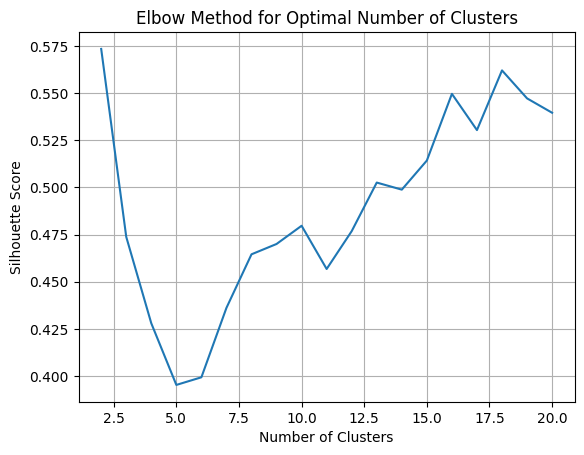

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_scores = []
for k in range(2, 21):

    kmeans = KMeans(n_clusters=k,n_init=20,random_state=42)
    kmeans.fit(customers[["Visit_Time", "Average_Expense"]])
    sil_scores.append(silhouette_score(customers[["Visit_Time", "Average_Expense"]], kmeans.labels_))


import matplotlib.pyplot as plt
plt.plot(range(2, 21), sil_scores)
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.grid(True)
plt.show()

from the above chart, 4 clusters maximizes the silhouette score.

**(e)** (6 points) Using the `cmeans` function from the `skfuzzy.cluster` library, cluster the customers into the number of clusters estimated from part (d).

In [10]:
from skfuzzy.cluster import cmeans

fc, W, u0, d, jm, p, pc = cmeans(customers[["Visit_Time", "Average_Expense"]].T, c=4, m=1.25, error=0.001, maxiter=1000, seed=42)

In [11]:
W.shape

(4, 60)

In [12]:
customers.shape

(60, 4)

**(f)** (10 points) Change the likelihoods to cluster labels using 70% as threshold. Describe each of the clusters from part (d).

In [15]:
import numpy as np

customers["Cluster"] = np.nan

# Changing likelihoods to labels
customers["Cluster"] = np.where(W[0] > 0.7, 0, customers["Cluster"])
customers["Cluster"] = np.where(W[1] > 0.7, 1, customers["Cluster"])
customers["Cluster"] = np.where(W[2] > 0.7, 2, customers["Cluster"])
customers["Cluster"] = np.where(W[3] > 0.7, 3, customers["Cluster"])

# Checking for proportion of points assigned to each cluster
customers["Cluster"].value_counts(normalize=True)

Cluster
0.0    0.350877
3.0    0.280702
2.0    0.210526
1.0    0.157895
Name: proportion, dtype: float64